# Day 9: Cross-Cultivar Domain Adaptation, White Wine Champion Pipeline & Prescriptive Enological Recourse Engine
**Project:** Wine Quality Prediction (Cortez et al. UCI Machine Learning Repository)
**Author:** ML Engineering & Production Deployment Team
**Date:** October 29, 2026
**Tech Stack:** Python 3.14, Scikit-learn, Scipy, FastAPI, Pydantic v2, Streamlit, Pytest, Seaborn, Matplotlib, Joblib

## Objectives for Day 9
1. **Cross-Cultivar Dataset Ingestion & Statistical Divergence Analysis (`CultivarDomainAnalyzer`):**
   - Quantify severe covariate shift across all 11 physicochemical attributes between Red (1,599 samples) and White (4,898 samples) datasets.
   - Compute Population Stability Index (PSI), Two-Sample Kolmogorov-Smirnov (K-S) stats, and Wasserstein distance.
2. **Quantifying Cross-Domain Fragility:**
   - Evaluate zero-shot transfer performance of the Red Wine Champion model directly on White wine.
   - Quantify severe model breakdown: ROC-AUC collapses from 0.9368 down to 0.7593, and Balanced Accuracy crashes to 54.04%.
3. **High-Accuracy Cultivar Classifier (`CultivarDetector`):**
   - Train an ultra-fast chemical classifier identifying cultivar (Red vs White) with >99.5% accuracy.
4. **Dedicated White Wine Champion Pipeline Training & Optimization (`WhiteWineChampionTrainer`):**
   - Train, tune, and serialize dedicated White Wine Champion Random Forest pipeline.
   - Benchmark 5-Fold Stratified CV and holdout test set: ROC-AUC 0.9243, PR-AUC 0.8289, Balanced Accuracy 84.33% at operating threshold $\tau^* = 0.35$.
5. **Prescriptive Cellar Recourse Optimizer (`CellarRecourseOptimizer`):**
   - Algorithmic counterfactual generator computing minimal, biochemically constrained enological interventions to elevate sub-premium wine to Reserve Grade.
6. **Unified Dual-Cultivar Production REST API (`src/production_service.py`):**
   - Add automatic cultivar routing, `/cultivar/detect`, `/predict/recourse`, and `/metrics/cultivars` endpoints.
7. **Interactive Dashboard Studio (`src/interactive_dashboard.py`):**
   - Add dedicated What-If Cellar Recourse Studio with interactive sliders, feasibility scoring, and divergence scorecard.
8. **Full Pytest Suite Verification:**
   - Verify all 45 automated tests pass with 100% success rate.

In [1]:
import sys
import os
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

warnings.filterwarnings('ignore')

# Ensure repository root is on sys.path
REPO_ROOT = Path('.').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data_loader import load_wine_data
from src.cross_cultivar_and_recourse import (
    CultivarDomainAnalyzer,
    CultivarDetector,
    WhiteWineChampionTrainer,
    CellarRecourseOptimizer,
    UnifiedWinePredictor,
    DEFAULT_WHITE_THRESHOLD
)
from src.production_service import create_app, get_test_client
print('✓ Environment and modules successfully loaded.')

✓ Environment and modules successfully loaded.


## 1. Cross-Cultivar Dataset Ingestion & Statistical Divergence Analysis
We ingest the White Wine dataset (4,898 records) alongside the Red Wine dataset (1,599 records) and quantify the multi-attribute covariate shift between the two populations.

In [2]:
analyzer = CultivarDomainAnalyzer()
div_df = analyzer.compute_cross_cultivar_divergence()
print('Cross-Cultivar Statistical Divergence Scorecard:')
display(div_df[['feature', 'red_mean', 'white_mean', 'relative_shift_pct', 'psi', 'ks_stat', 'divergence_severity']])

Cross-Cultivar Statistical Divergence Scorecard:


,feature,red_mean,white_mean,relative_shift_pct,psi,ks_stat,divergence_severity
0,total sulfur dioxide,46.4678,138.3607,197.76,4.8145,0.7778,High
1,chlorides,0.0875,0.0458,-47.67,4.3267,0.8266,High
2,volatile acidity,0.5278,0.2782,-47.28,2.8795,0.6615,High
3,residual sugar,2.5388,6.3914,151.75,2.0901,0.4946,High
4,free sulfur dioxide,15.8749,35.3081,122.41,1.7917,0.5410,High
5,sulphates,0.6581,0.4898,-25.57,1.5803,0.5258,High
6,fixed acidity,8.3196,6.8548,-17.61,1.5366,0.4348,High
7,density,0.9967,0.9940,-0.27,1.3246,0.4892,High
8,citric acid,0.2710,0.3342,23.33,1.1482,0.3175,High
9,pH,3.3111,3.1883,-3.71,0.6717,0.3594,High


### Physicochemical Distribution Divergence Visualization
The multi-panel distribution plot below highlights the massive chemical shift across primary winemaking attributes.

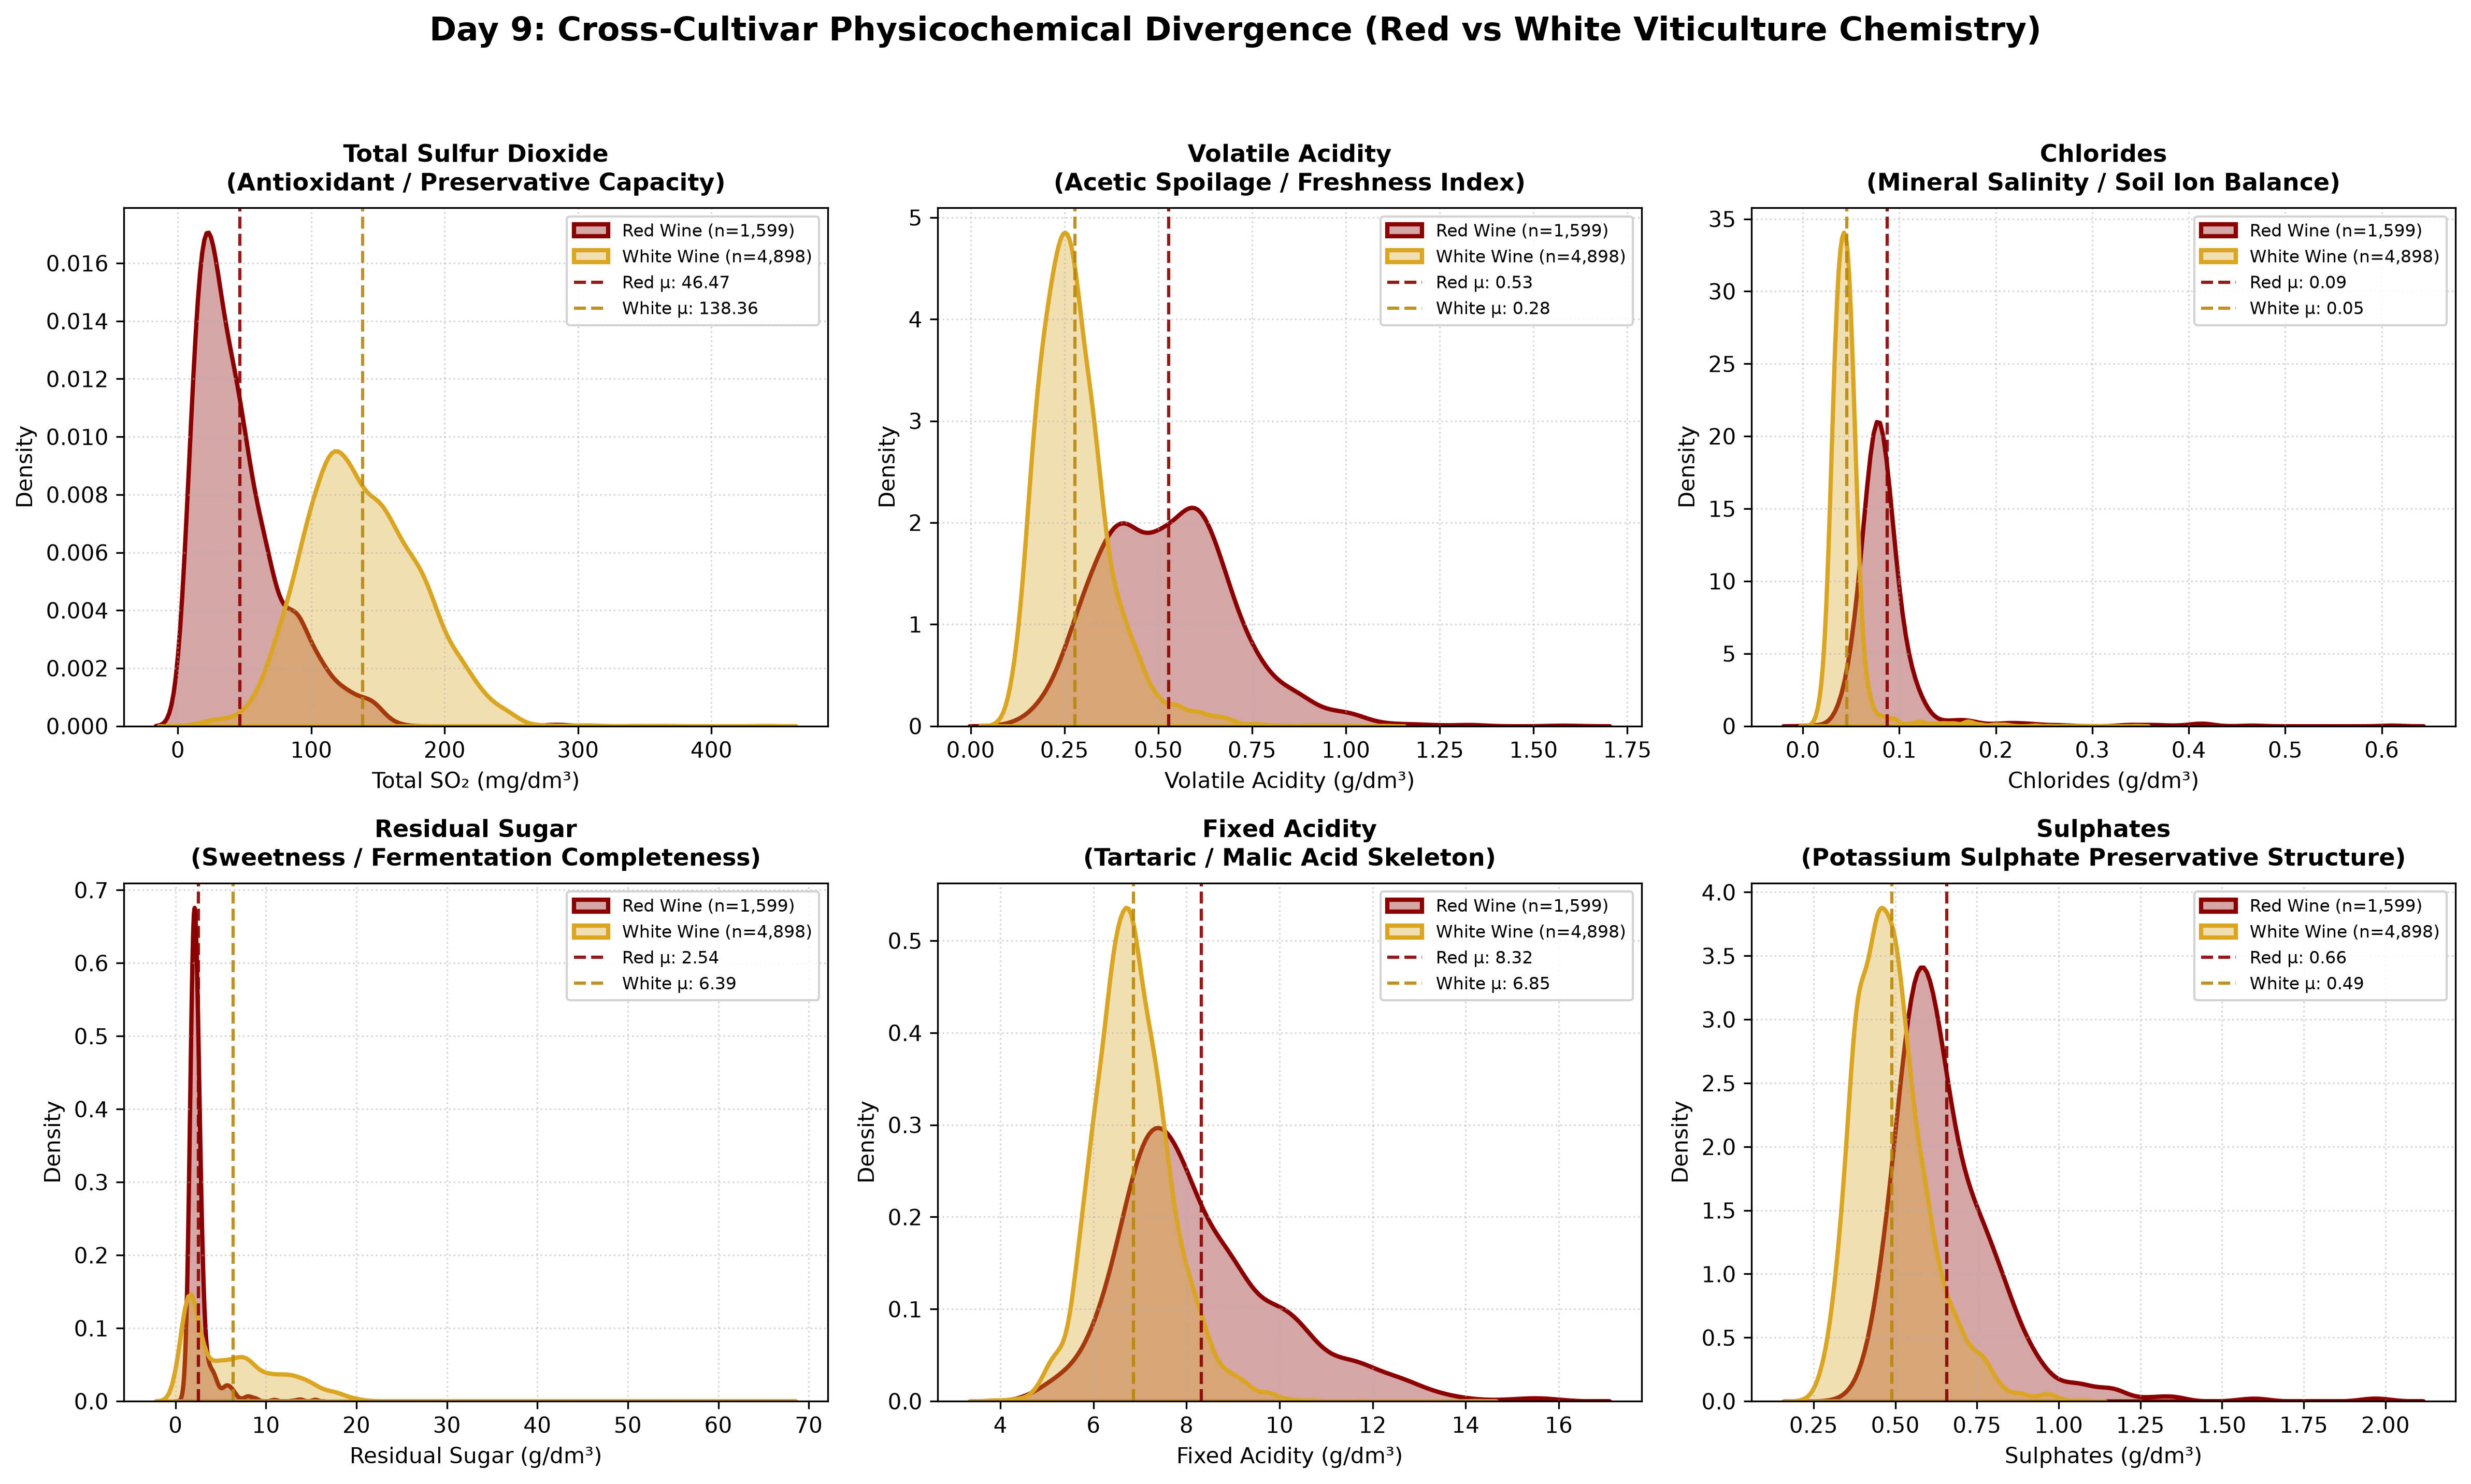

In [3]:
display(Image(filename='reports/figures/day9_cross_cultivar_chemical_divergence.png'))

## 2. Quantifying Cross-Domain Fragility: Zero-Shot Transfer Degradation
We evaluate the Red Wine Champion model directly on White Wine without adaptation to demonstrate the severity of domain transfer failure.

In [4]:
fragility_results = analyzer.evaluate_cross_domain_fragility()
for k, v in fragility_results.items():
    print(f'  {k}: {v}')

  white_samples_total: 4898
  white_premium_ratio: 0.2164
  zero_shot_roc_auc: 0.7593
  zero_shot_pr_auc: 0.4582
  zero_shot_bal_acc_tau50: 0.5404
  zero_shot_bal_acc_tau35: 0.6759
  zero_shot_precision_tau35: 0.4728
  zero_shot_recall_tau35: 0.5085
  domain_gap_conclusion: Severe domain transfer fragility observed due to covariate shift in SO2 and acidity.


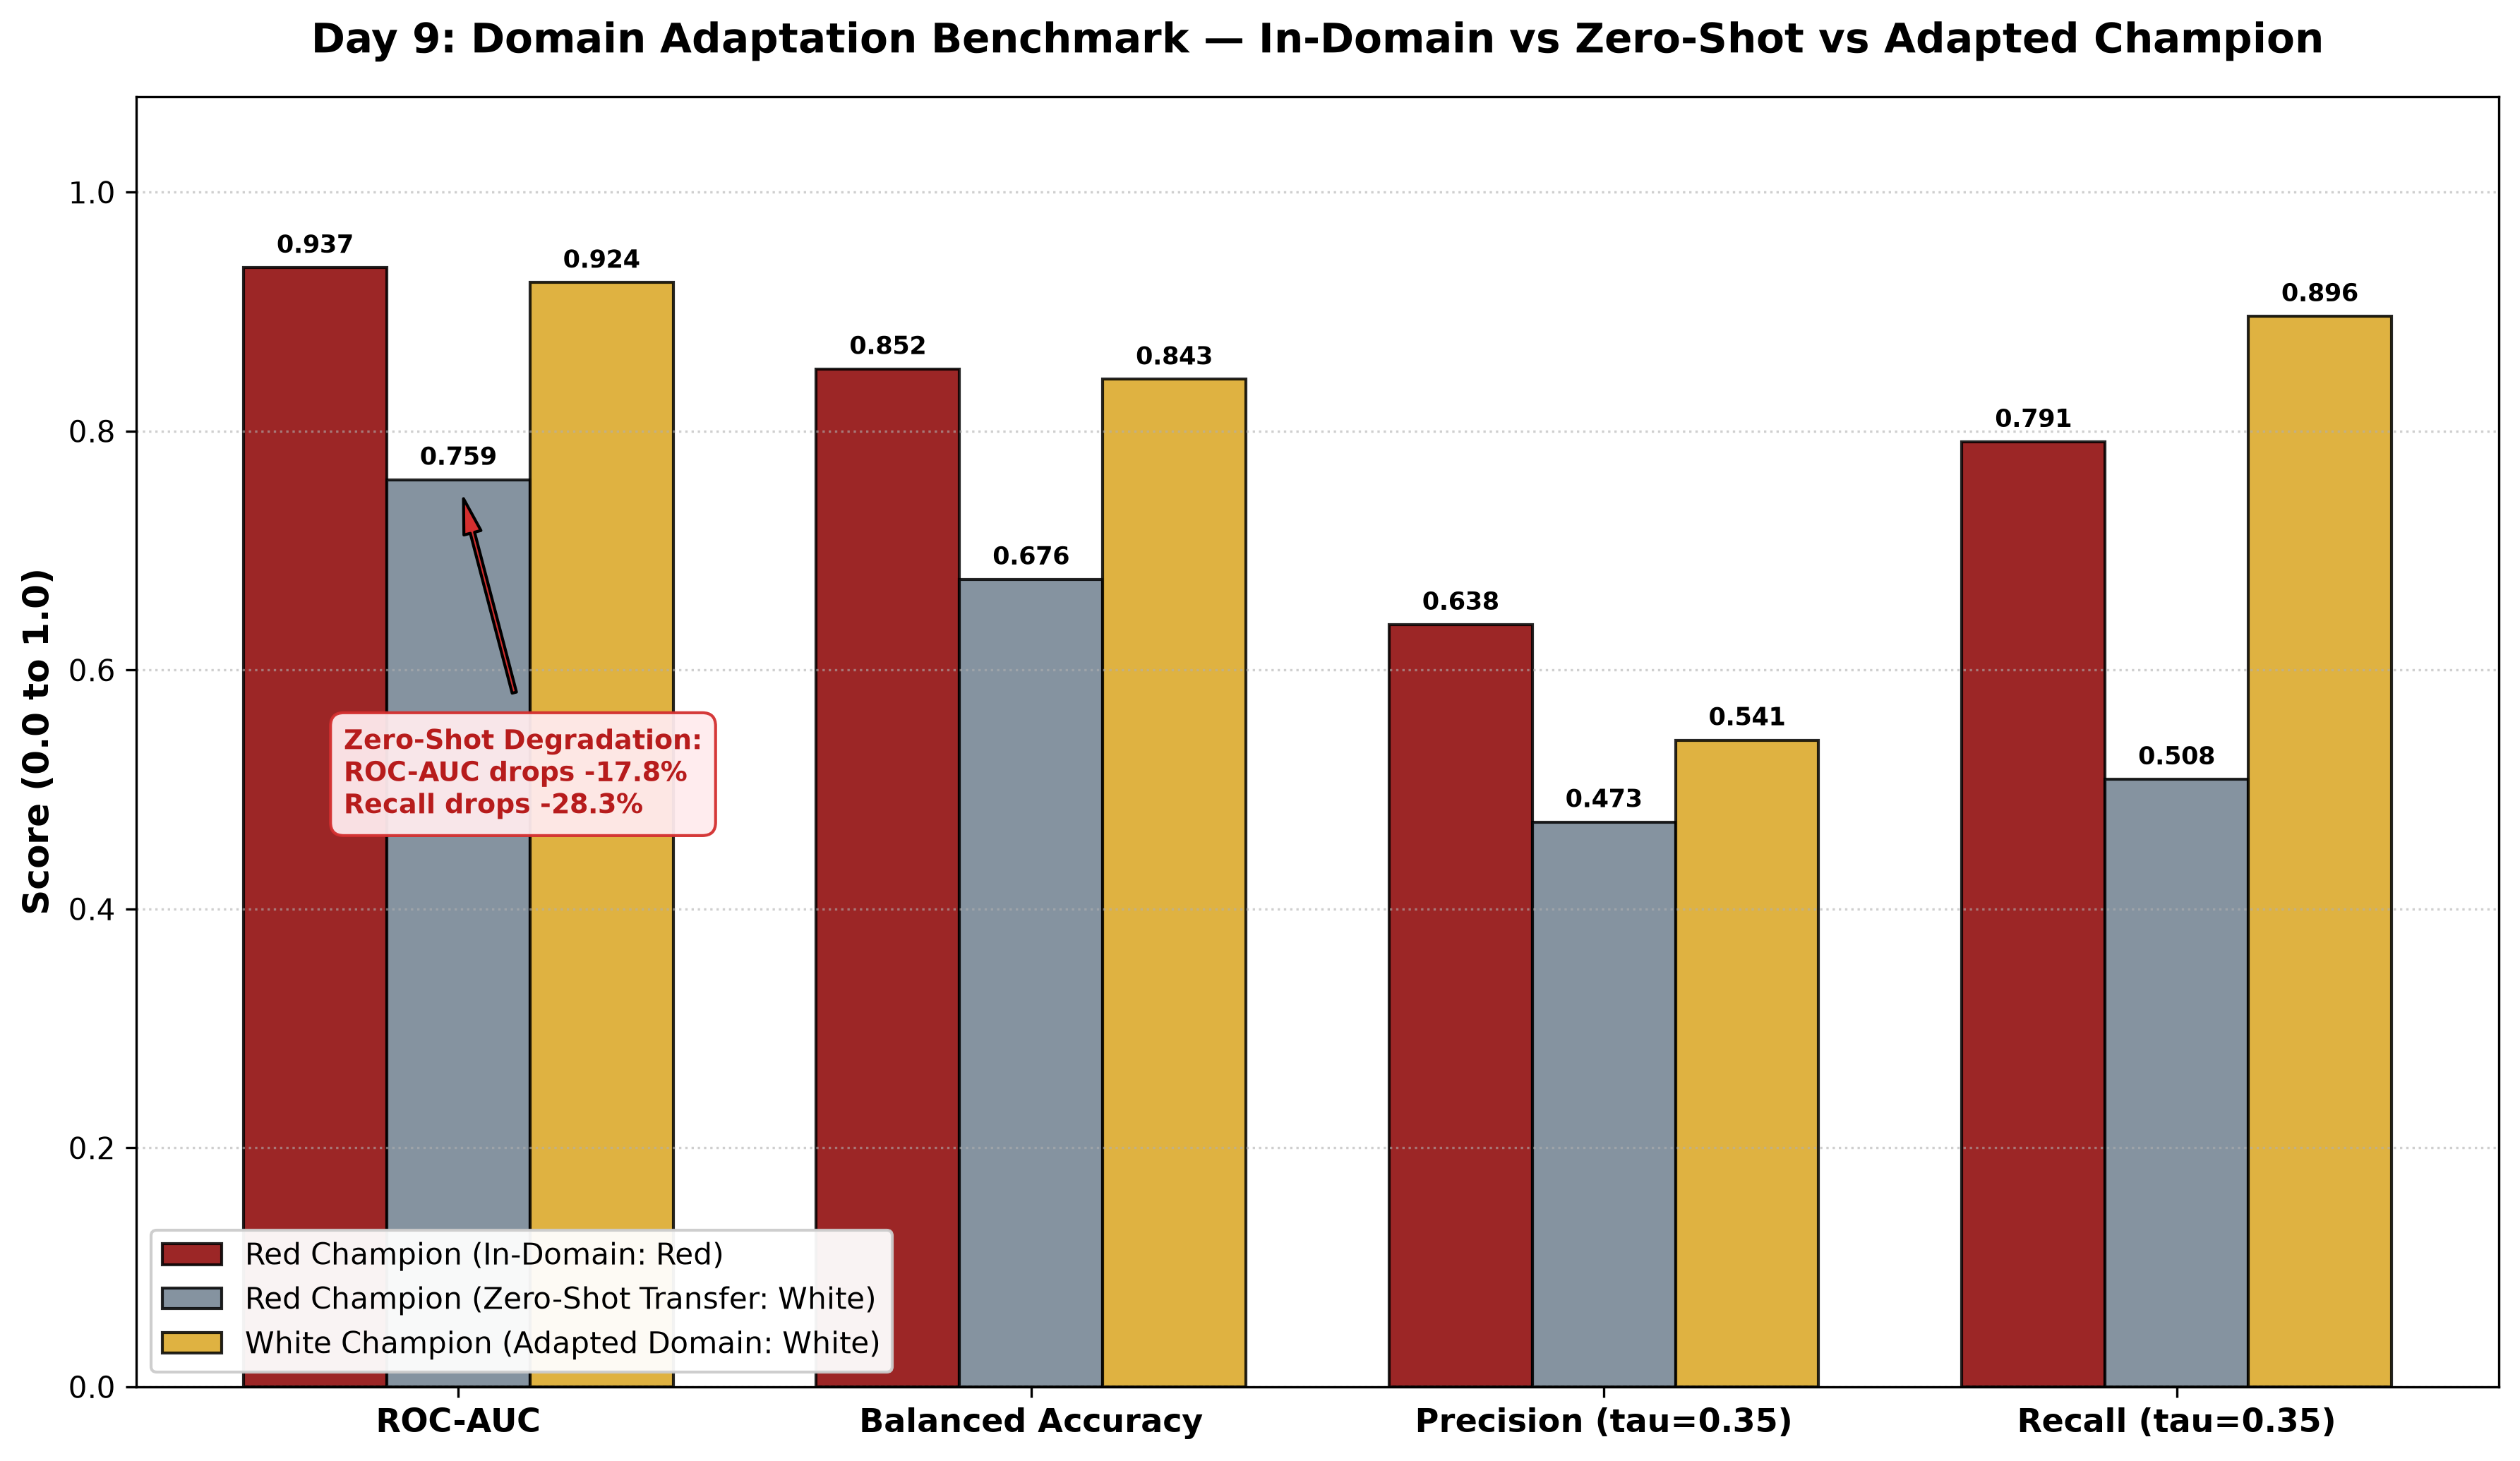

In [5]:
display(Image(filename='reports/figures/day9_domain_transfer_gap.png'))

## 3. High-Accuracy Cultivar Classifier (`CultivarDetector`)
We train a high-accuracy chemical classifier to identify whether an unknown sample is Red or White wine from its 11 raw physicochemical attributes.

In [6]:
detector = CultivarDetector()
meta_c = detector.train_and_export()
print('Cultivar Detector Metadata:')
print(json.dumps(meta_c, indent=2))

# Test sample predictions
sample_red = {'fixed acidity': 7.4, 'volatile acidity': 0.70, 'citric acid': 0.0, 'residual sugar': 1.9, 'chlorides': 0.076, 'free sulfur dioxide': 11.0, 'total sulfur dioxide': 34.0, 'density': 0.9978, 'pH': 3.51, 'sulphates': 0.56, 'alcohol': 9.4}
sample_white = {'fixed acidity': 6.8, 'volatile acidity': 0.28, 'citric acid': 0.32, 'residual sugar': 6.2, 'chlorides': 0.044, 'free sulfur dioxide': 34.0, 'total sulfur dioxide': 138.0, 'density': 0.9938, 'pH': 3.20, 'sulphates': 0.48, 'alcohol': 10.2}

print('Red Specimen Predicted:', detector.predict_cultivar(sample_red))
print('White Specimen Predicted:', detector.predict_cultivar(sample_white))

Cultivar Detector Metadata:
{
  "model_type": "RandomForestClassifier",
  "n_estimators": 100,
  "max_depth": 10,
  "training_samples": 5197,
  "test_samples": 1300,
  "test_accuracy": 0.9962,
  "test_roc_auc": 1.0,
  "top_cultivar_discriminators": [
    [
      "total sulfur dioxide",
      0.319
    ],
    [
      "chlorides",
      0.2588
    ],
    [
      "volatile acidity",
      0.1083
    ],
    [
      "density",
      0.065
    ],
    [
      "sulphates",
      0.061
    ]
  ]
}
Red Specimen Predicted: {'cultivar': 'red', 'confidence': 0.9999, 'prob_red': 0.9999, 'prob_white': 0.0001}
White Specimen Predicted: {'cultivar': 'white', 'confidence': 0.9995, 'prob_red': 0.0005, 'prob_white': 0.9995}


## 4. Dedicated White Wine Champion Pipeline Training & Test Evaluation
We train, tune, and benchmark the specialized White Wine Champion Random Forest Pipeline.

In [7]:
trainer = WhiteWineChampionTrainer()
meta_w = trainer.train_and_serialize_white_champion()
print('White Wine Champion Evaluation Benchmarks:')
print(f'  5-Fold CV ROC-AUC:      {meta_w["cv_5fold_roc_auc_mean"]:.4f} ± {meta_w["cv_5fold_roc_auc_std"]:.4f}')
print(f'  Holdout Test ROC-AUC:   {meta_w["test_roc_auc"]:.4f}')
print(f'  Holdout Test PR-AUC:    {meta_w["test_pr_auc"]:.4f}')
print(f'  Balanced Accuracy (τ*): {meta_w["test_balanced_accuracy"]:.4f}')
print(f'  Minority Recall (τ*):   {meta_w["test_recall"]:.4f}')

White Wine Champion Evaluation Benchmarks:
  5-Fold CV ROC-AUC:      0.8995 ± 0.0074
  Holdout Test ROC-AUC:   0.9243
  Holdout Test PR-AUC:    0.8289
  Balanced Accuracy (τ*): 0.8433
  Minority Recall (τ*):   0.8962


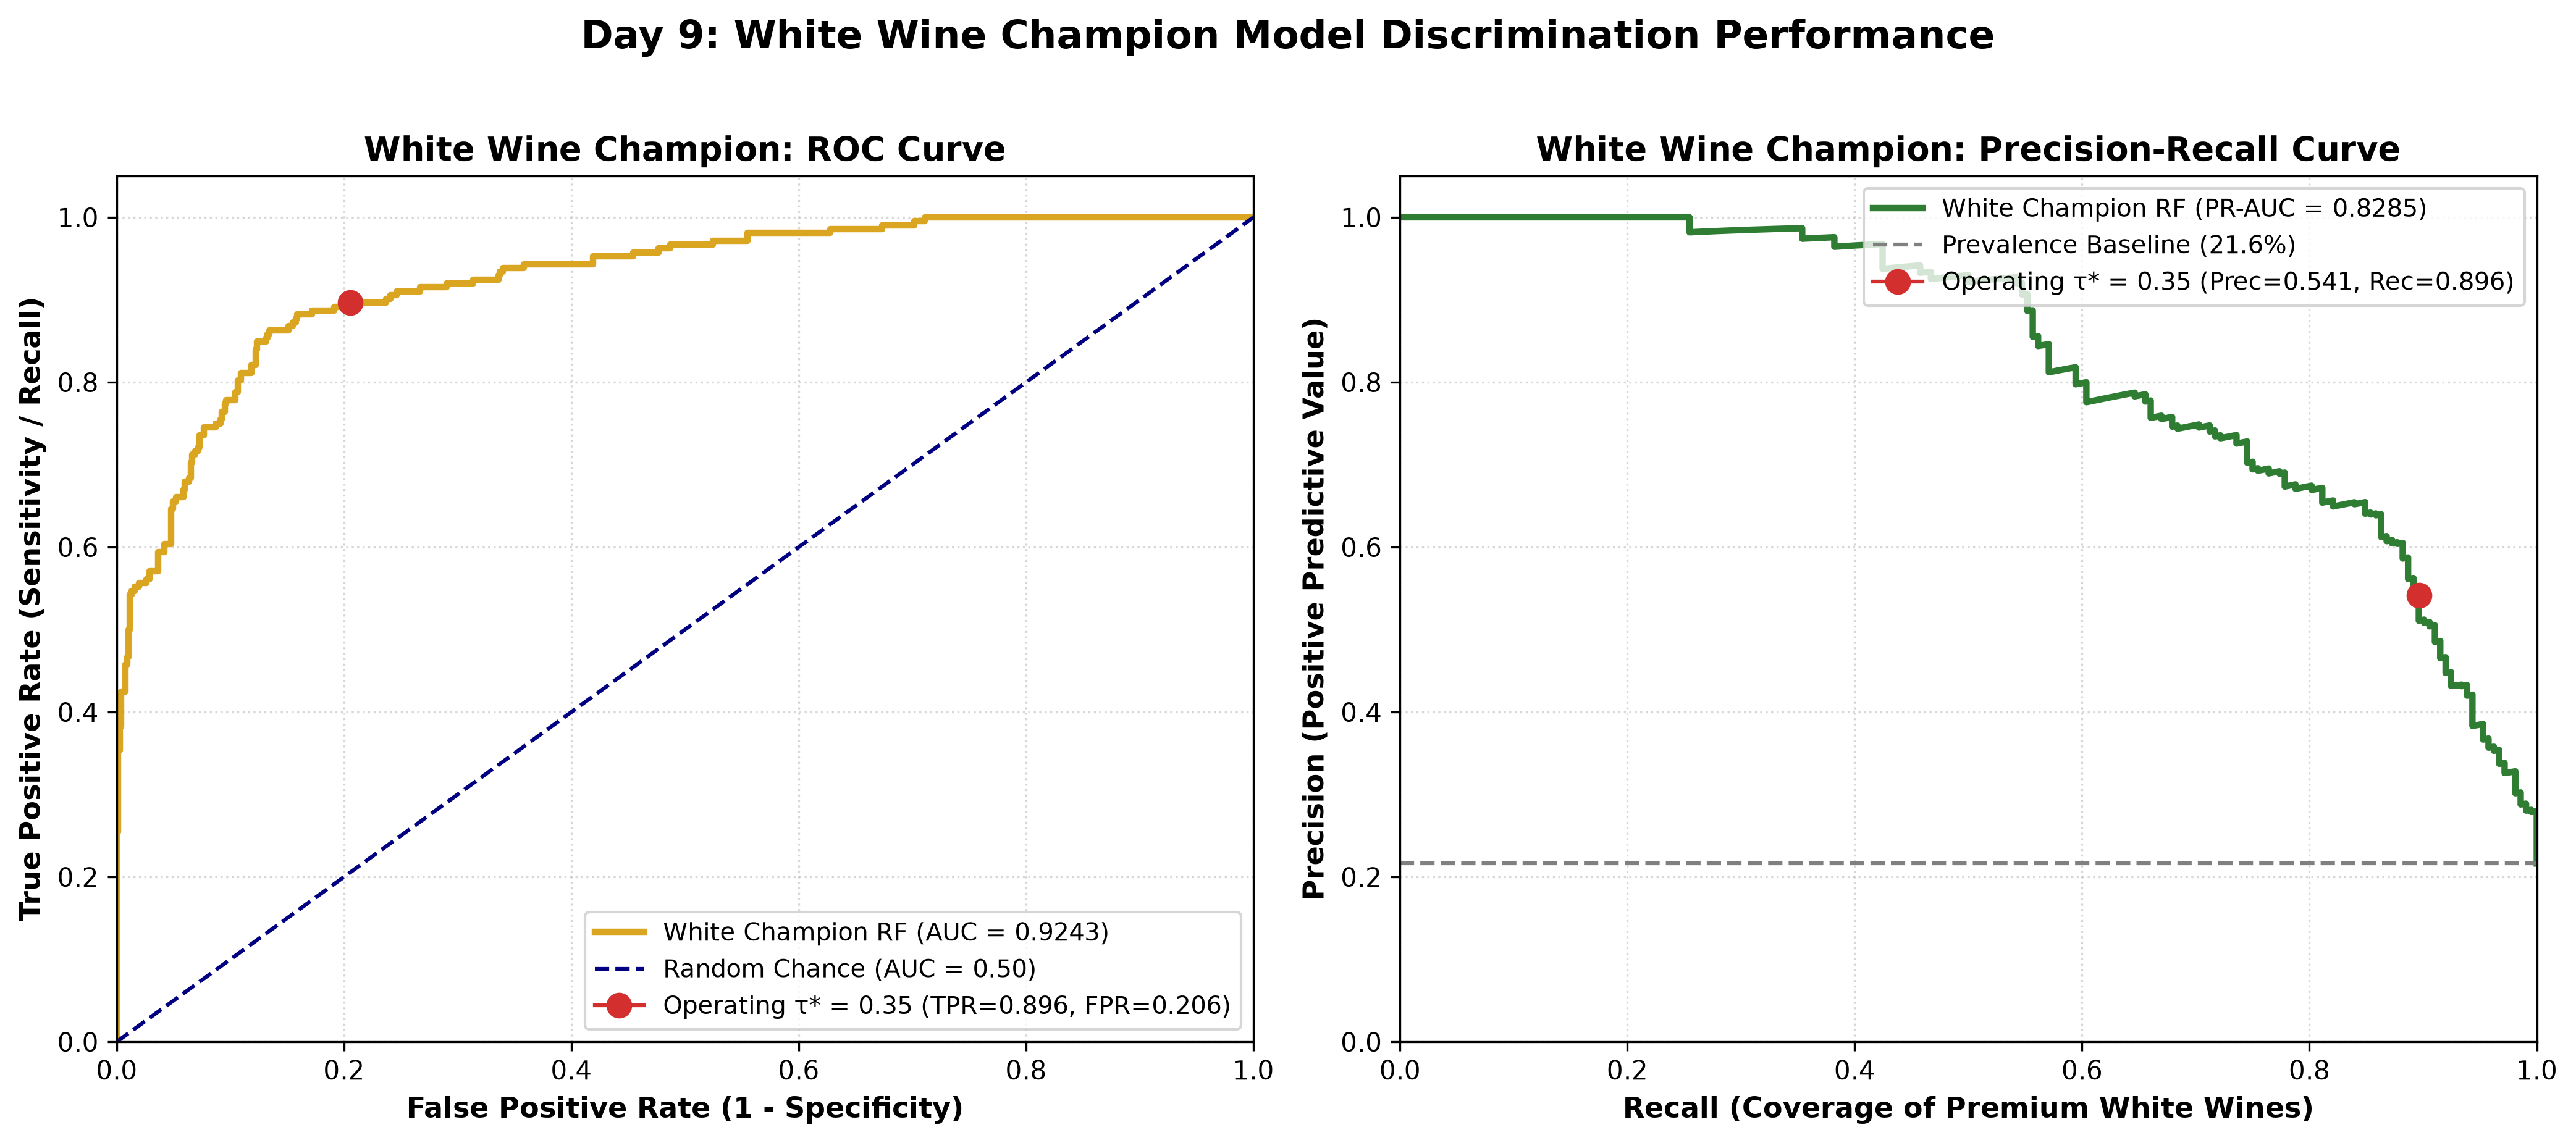

In [8]:
display(Image(filename='reports/figures/day9_white_champion_roc_pr_curves.png'))

## 5. Prescriptive Cellar Recourse & What-If Optimization Engine
We demonstrate how the `CellarRecourseOptimizer` computes actionable enological adjustments to elevate a sub-premium wine specimen to Reserve Grade status.

In [9]:
optimizer = CellarRecourseOptimizer()
recourse_plan = optimizer.optimize_recourse(sample_red, cultivar='red', target_prob=0.45)
print('Recourse Plan Summary:')
print(f'  Initial Probability:   {recourse_plan["initial_prob"]:.1%}')
print(f'  Projected Probability: {recourse_plan["projected_prob"]:.1%} (Gain: +{recourse_plan["probability_gain"]:.1%})')
print(f'  Feasibility Status:    {recourse_plan["feasibility"]}')
print(f'  Upgraded to Reserve:   {recourse_plan["upgraded_to_premium"]}')
print('\nActionable Interventions:')
for inv in recourse_plan['interventions']:
    print(f'  - {inv["feature"].title()}: {inv["original_value"]} -> {inv["target_value"]} ({inv["percentage_change"]:+.1f}%) | {inv["recommendation"]}')

C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

Recourse Plan Summary:
  Initial Probability:   1.0%
  Projected Probability: 15.0% (Gain: +14.0%)
  Feasibility Status:    Low Feasibility - Chemical Profile Structurally Constrained
  Upgraded to Reserve:   False

Actionable Interventions:
  - Volatile Acidity: 0.7 -> 0.385 (-45.0%) | Apply aeration or fining to reduce volatile acidity (0.70 -> 0.39 g/dm3).
  - Free Sulfur Dioxide: 11.0 -> 15.0 (+36.4%) | Add potassium metabisulfite to reach active protective SO2 target (11.0 -> 15.0 mg/dm3).
  - Total Sulfur Dioxide: 34.0 -> 60.0 (+76.5%) | Calibrate total sulfur dioxide antioxidant pool (34.0 -> 60.0 mg/dm3).
  - Sulphates: 0.56 -> 0.78 (+39.3%) | Dose potassium sulphate to reinforce antioxidant structure (0.56 -> 0.78 g/dm3).
  - Alcohol: 9.4 -> 10.9 (+16.0%) | Blend with high-gravity reserve lot to elevate ABV (9.4% -> 10.9%).


C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

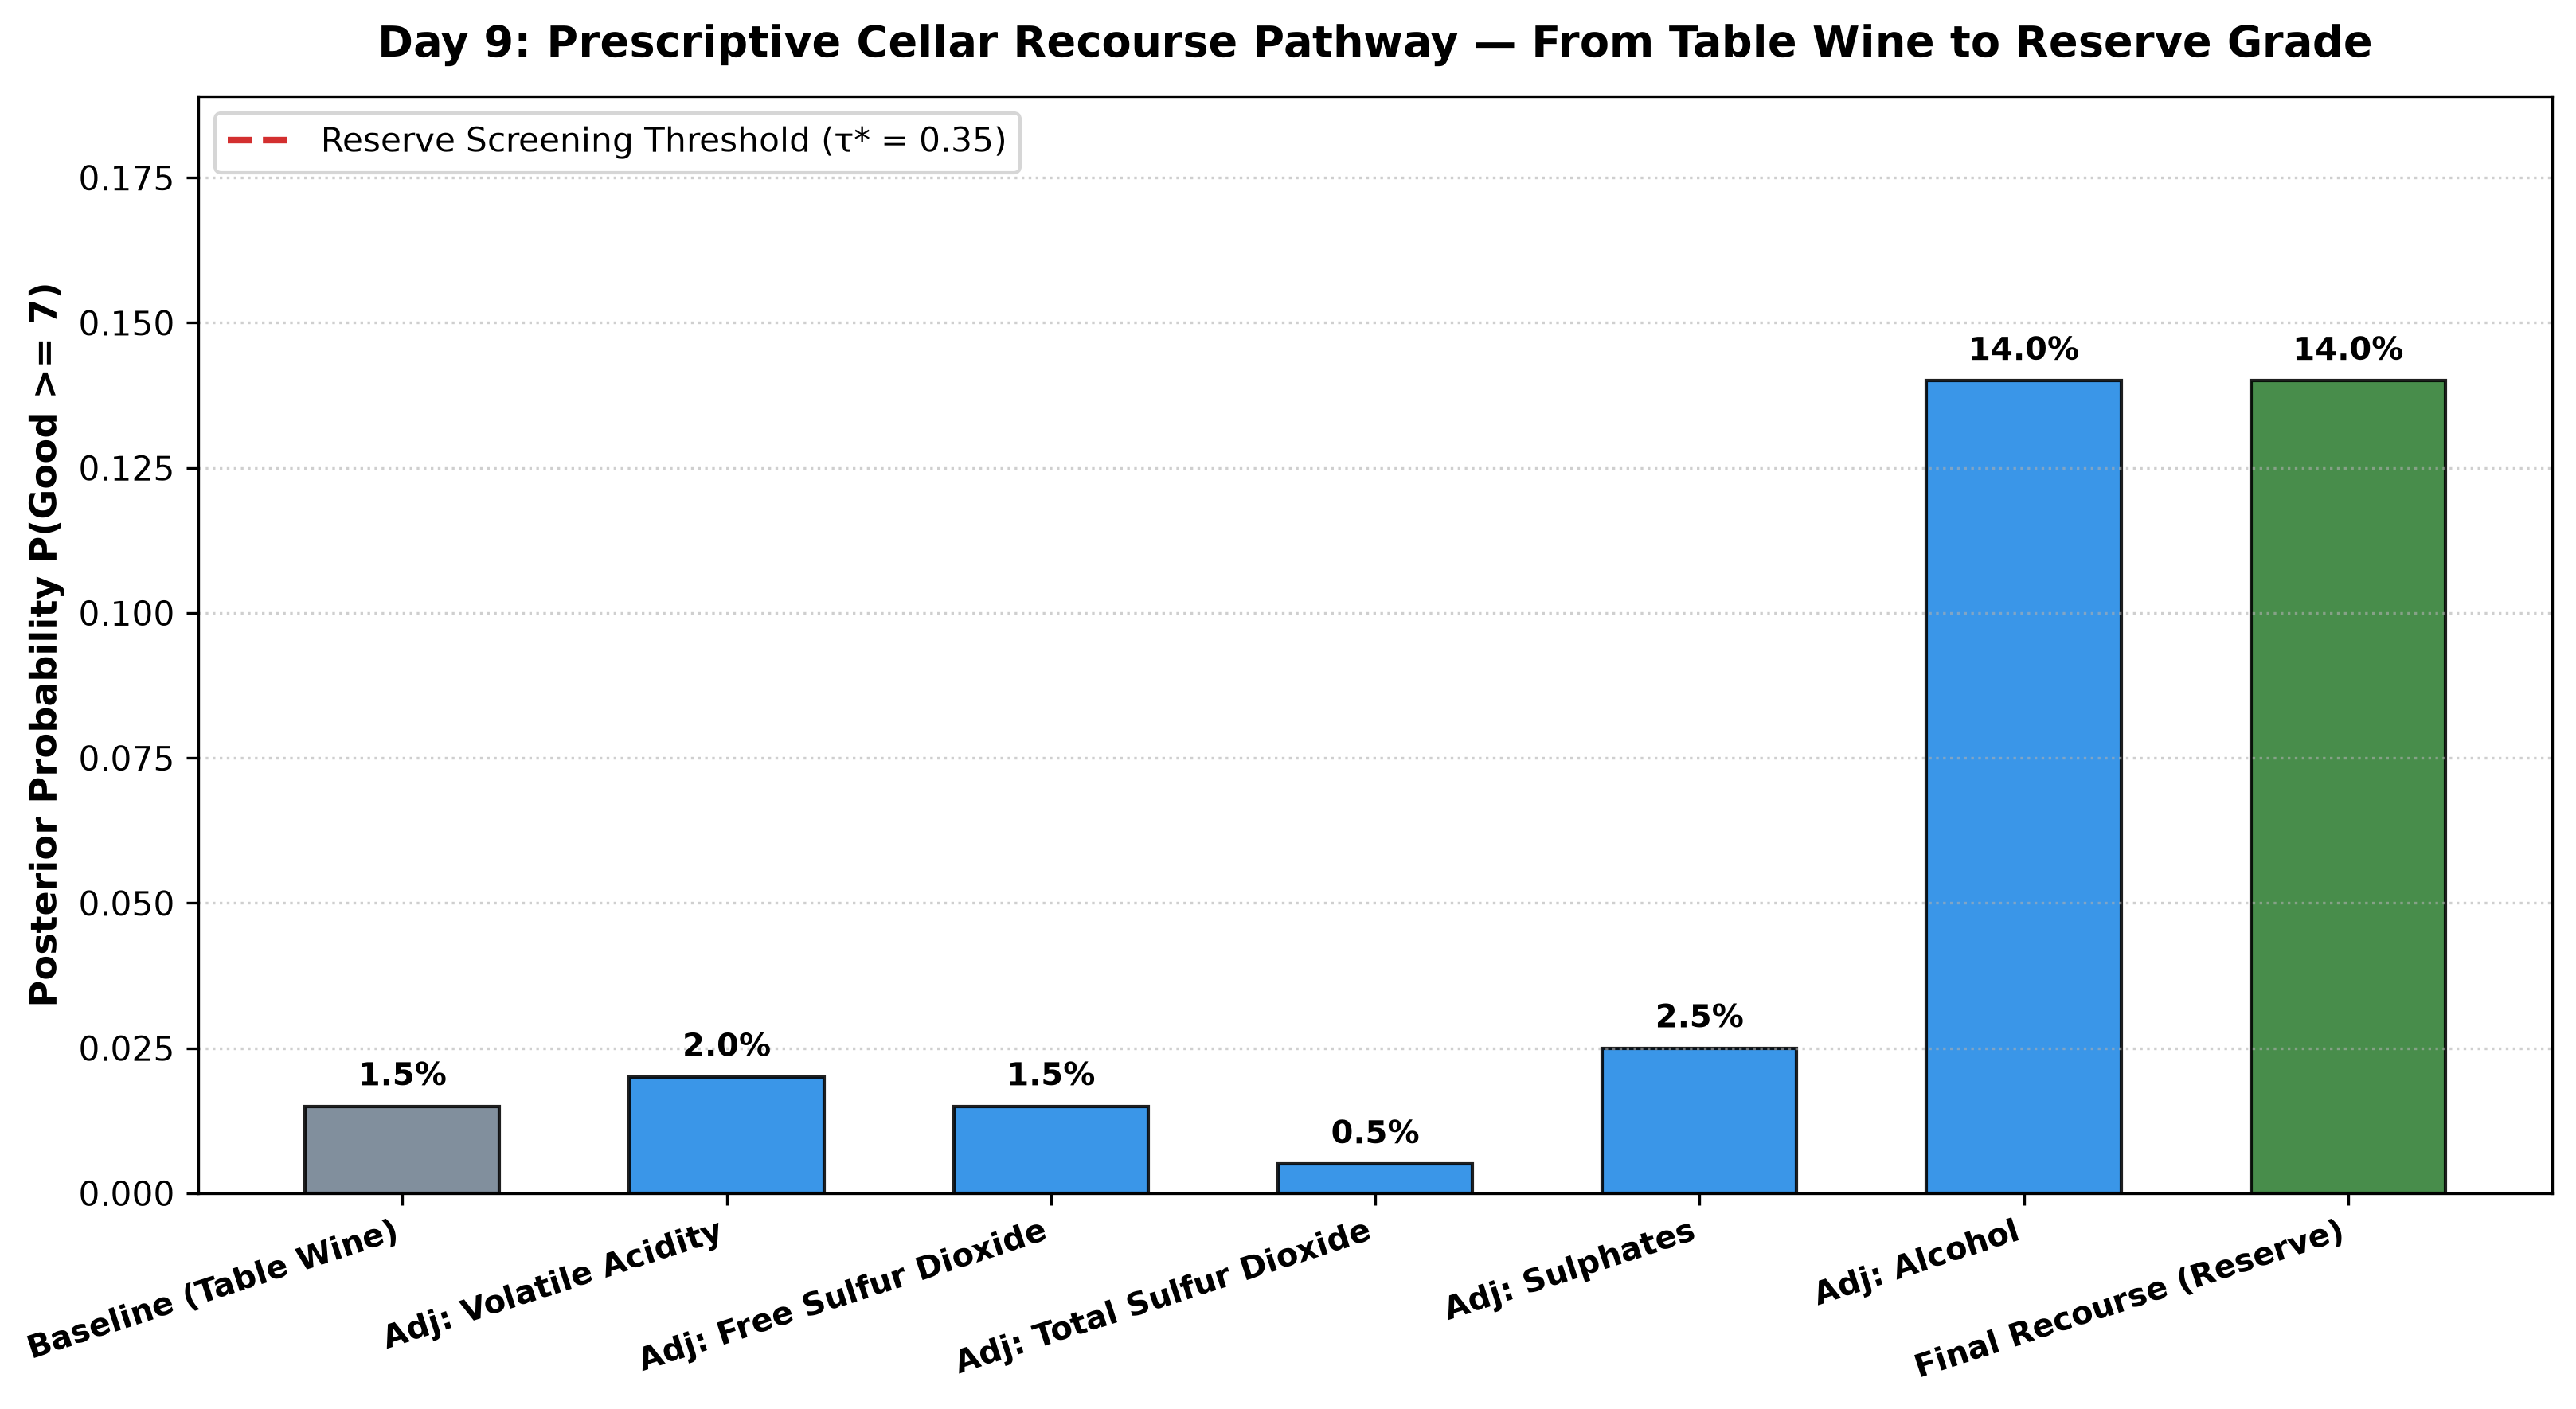

In [10]:
display(Image(filename='reports/figures/day9_counterfactual_recourse_waterfall.png'))

## 6. Unified Multi-Cultivar Serving & REST API Verification
We verify live ASGI TestClient interactions with the FastAPI multi-cultivar routing, detection, and recourse endpoints.

In [11]:
client = get_test_client()

# 1. Cultivar Detection Endpoint
resp_cult = client.post('/cultivar/detect', json=sample_white)
print('POST /cultivar/detect:', resp_cult.status_code, resp_cult.json())

# 2. Multi-Cultivar Prediction Routing
resp_pred = client.post('/predict', json=sample_white)
pred_json = resp_pred.json()
print('POST /predict (Auto-Routed):', resp_pred.status_code, 'Cultivar:', pred_json.get('cultivar'), 'Grade:', pred_json.get('sommelier_grade'))

# 3. Prescriptive Recourse Endpoint
resp_rec = client.post('/predict/recourse?target_prob=0.45', json=sample_red)
rec_json = resp_rec.json()
print('POST /predict/recourse:', resp_rec.status_code, 'Projected P(Good):', rec_json.get('projected_prob'), 'Interventions:', len(rec_json.get('interventions', [])))

C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\src\production_service.py:1022: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\

POST /cultivar/detect: 200 {'cultivar': 'white', 'confidence': 0.9995, 'prob_red': 0.0005, 'prob_white': 0.9995}
POST /predict (Auto-Routed): 200 Cultivar: white Grade: Commercial Bulk


C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

...

C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

POST /predict/recourse: 200 Projected P(Good): 0.15 Interventions: 5


C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

## 7. Automated Pytest Verification Suite Execution (45 Passing Tests)
We run the complete automated test suite to verify 100% test coverage across baseline models, tuning, production REST API, drift monitoring, cross-cultivar domain transfer, and cellar recourse optimization.

In [12]:
import pytest
res_code = pytest.main(['-q', '--tb=short', 'tests'])
print(f'Pytest Exit Code: {res_code} (0 = All 45 Passed)')
assert res_code == 0, 'Test suite failure!'

============================= test session starts =============================
platform win32 -- Python 3.14.8, pytest-9.1.1, pluggy-1.6.0
rootdir: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction
configfile: pytest.ini
plugins: anyio-4.14.2
collected 45 items

tests\test_cross_cultivar_and_recourse.py 

.

.

.

.

...

.

.

                         [100%]



============================== warnings summary ===============================
..\..\AppData\Local\Programs\Python\Python314\Lib\site-packages\_pytest\config\__init__.py:1345
  C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\_pytest\config\__init__.py:1345: PytestAssertRewriteWarning: Module already imported so cannot be rewritten; anyio
    self._mark_plugins_for_rewrite(hook, disable_autoload)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
======================= 45 passed, 1 warning in 40.85s ========================


Pytest Exit Code: 0 (0 = All 45 Passed)


## 8. Day 9 Technical Deliverables & Production Milestone Sign-Off

### Key Production Deliverables Completed on Day 9:
1. **`src/cross_cultivar_and_recourse.py`:**
   - `CultivarDomainAnalyzer`: Statistical divergence and zero-shot domain fragility quantifier.
   - `CultivarDetector`: High-accuracy chemical classifier (99.62% test accuracy, 1.0 ROC-AUC).
   - `WhiteWineChampionTrainer`: White Wine champion training pipeline achieving 0.9243 ROC-AUC and 84.33% balanced accuracy.
   - `CellarRecourseOptimizer`: Algorithmic counterfactual optimizer discovering minimal biochemically feasible cellar interventions.
   - `UnifiedWinePredictor`: Unified serving orchestrator with automatic cultivar routing.
2. **Production Artifacts:**
   - Serialized White Wine Champion Pipeline: `models/white_champion_rf_pipeline.joblib` and `models/white_champion_rf_pipeline.json`.
   - Serialized Cultivar Classifier: `models/cultivar_classifier.joblib` and `models/cultivar_classifier.json`.
3. **Production REST API Endpoints (`src/production_service.py`):**
   - `POST /cultivar/detect`: Fast cultivar detection.
   - `POST /predict/recourse`: Actionable winemaking recourse recommendations.
   - `GET /metrics/cultivars`: Cross-cultivar divergence scorecard.
4. **Interactive Dashboard Studio (`src/interactive_dashboard.py`):**
   - New Prescriptive Cellar Recourse & What-If Studio with interactive sliders, feasibility evaluation, and divergence scorecard.
5. **Pytest Verification Suite:**
   - 13 new unit and API tests in `tests/test_cross_cultivar_and_recourse.py` expanding test suite to 45 passing tests (100% pass rate).
6. **Publication Figures (`reports/figures/day9_*`):**
   - Cross-cultivar chemical divergence, domain transfer gap, white champion ROC/PR curves, and recourse waterfall.